<a href="https://colab.research.google.com/github/GLchaitanya/Dav-LAB/blob/main/pgm5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats


In [2]:
data = {
    'Employee':['A','B','C','D','E','F','G','H','I','J','K','L','M'],
    'Salary':['25000','30000','28000','29500','32000','35000','50000','76000','78000','80000','86000','150000','200000']
}

In [3]:
df = pd.DataFrame(data)

In [41]:
print(data)

{'Employee': ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M'], 'Salary': ['25000', '30000', '28000', '29500', '32000', '35000', '50000', '76000', '78000', '80000', '86000', '150000', '200000']}


In [4]:
print(df)

   Employee  Salary
0         A   25000
1         B   30000
2         C   28000
3         D   29500
4         E   32000
5         F   35000
6         G   50000
7         H   76000
8         I   78000
9         J   80000
10        K   86000
11        L  150000
12        M  200000


In [6]:
plt.figure(figsize=(10,6))


<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

<Axes: ylabel='Salary'>

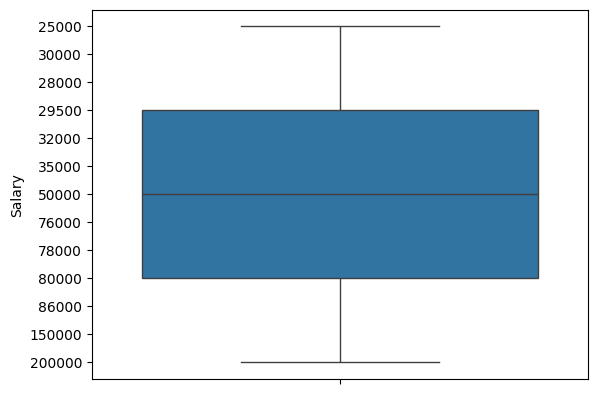

In [8]:
sns.boxplot(y=df['Salary'])


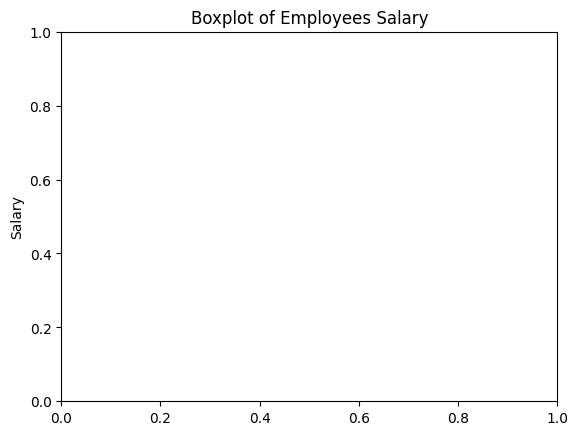

In [11]:
plt.title('Boxplot of Employees Salary')
plt.ylabel('Salary')
plt.show()

In [15]:
df['Salary'] = pd.to_numeric(df['Salary'])
Q1 = df['Salary'].quantile(0.25)
Q3 = df['Salary'].quantile(0.75)


In [16]:
print("Q1 =",Q1)
print("Q3 =",Q3)

Q1 = 30000.0
Q3 = 80000.0


In [17]:
IQR = Q3 - Q1
print("IQR =",IQR)

IQR = 50000.0


In [18]:
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR
print("Lower Limit =",lower_limit)
print("Upper Limit =",upper_limit)

Lower Limit = -45000.0
Upper Limit = 155000.0


In [19]:
outliers_iqr = df[(df['Salary'] < lower_limit) | (df['Salary'] > upper_limit)]
print("Outliers using IQR:")
print(outliers_iqr)

Outliers using IQR:
   Employee  Salary
12        M  200000


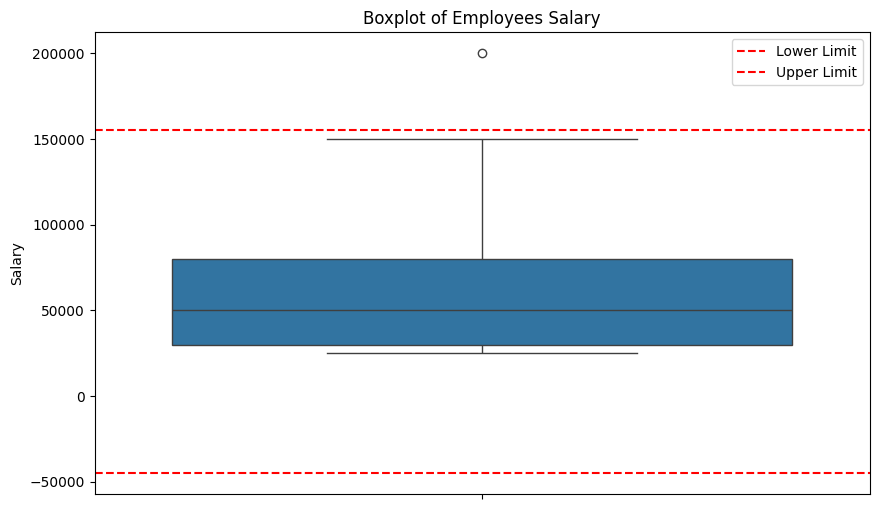

In [20]:
plt.figure(figsize=(10,6))
sns.boxplot(y=df['Salary'])
plt.axhline(lower_limit, color='r', linestyle='--', label='Lower Limit')
plt.axhline(upper_limit, color='r', linestyle='--', label='Upper Limit')
plt.title('Boxplot of Employees Salary')
plt.ylabel('Salary')
plt.legend()


In [23]:
df['Salary_IQR_Capped']= df['Salary'].clip(lower=lower_limit, upper=upper_limit)
print(df[['Salary','Salary_IQR_Capped']])

    Salary  Salary_IQR_Capped
0    25000              25000
1    30000              30000
2    28000              28000
3    29500              29500
4    32000              32000
5    35000              35000
6    50000              50000
7    76000              76000
8    78000              78000
9    80000              80000
10   86000              86000
11  150000             150000
12  200000             155000


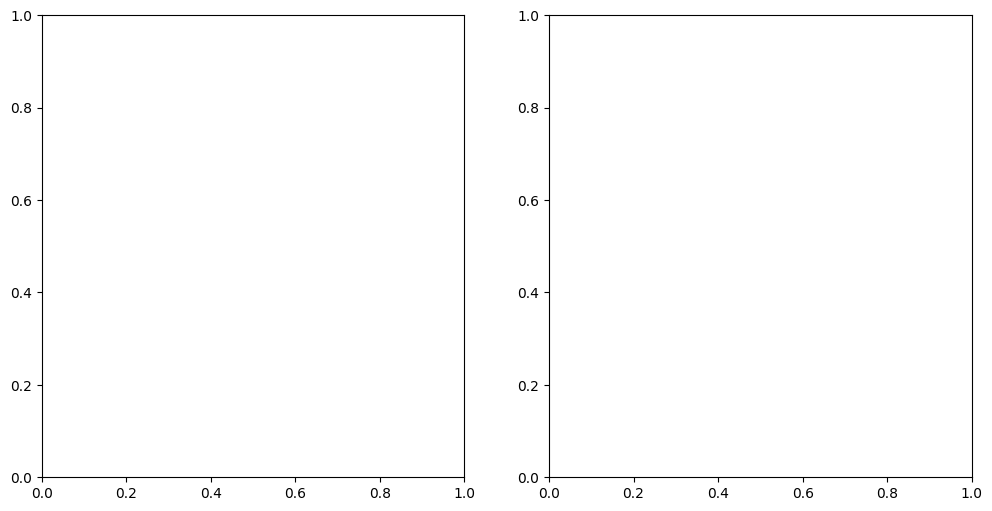

In [25]:
fig, axes = plt.subplots(1,2,figsize=(12,6))

In [26]:
sns.boxplot(y=df['Salary'],ax=axes[0])
axes[0].set_title('Before Capping')

Text(0.5, 1.0, 'Before Capping')

In [27]:
sns.boxplot(y=df['Salary_IQR_Capped'],ax=axes[1])
axes[1].set_title('After Capping')

Text(0.5, 1.0, 'After Capping')

In [28]:
plt.show()

In [29]:
df['Z_Score'] = stats.zscore(df['Salary'])
print(df[['Salary','Z_Score']])

    Salary   Z_Score
0    25000 -0.866096
1    30000 -0.768105
2    28000 -0.807301
3    29500 -0.777904
4    32000 -0.728908
5    35000 -0.670113
6    50000 -0.376138
7    76000  0.133420
8    78000  0.172616
9    80000  0.211813
10   86000  0.329403
11  150000  1.583697
12  200000  2.563615


In [30]:
z_outliers = df[abs(df['Z_Score']) > 3]
print("Outliers using Z-Score:")
print(z_outliers)

Outliers using Z-Score:
Empty DataFrame
Columns: [Employee, Salary, Salary_IQR_Capped, Salary_Labeled_Capped, Z_Score]
Index: []


In [31]:
df['Z_Outlier']= abs(df['Z_Score']) > 3
print(df[['Salary','Z_Score','Z_Outlier']])

    Salary   Z_Score  Z_Outlier
0    25000 -0.866096      False
1    30000 -0.768105      False
2    28000 -0.807301      False
3    29500 -0.777904      False
4    32000 -0.728908      False
5    35000 -0.670113      False
6    50000 -0.376138      False
7    76000  0.133420      False
8    78000  0.172616      False
9    80000  0.211813      False
10   86000  0.329403      False
11  150000  1.583697      False
12  200000  2.563615      False


In [32]:
mean = df['Salary'].mean()
std = df['Salary'].std()
print("Mean =",mean)
print("Standard Deviation =",std)

Mean = 69192.30769230769
Standard Deviation = 53108.19870067869


In [33]:
lower_z_limit = mean - 3 * std
upper_z_limit = mean + 3 * std
print("Lower Limit =",lower_z_limit)
print("Upper Limit =",upper_z_limit)

Lower Limit = -90132.28840972838
Upper Limit = 228516.90379434376


In [36]:
df['Salary_Z_Capped'] = df['Salary'].clip(lower=lower_z_limit, upper=upper_z_limit)
print(df[['Salary','Salary_Z_Capped']])
#

    Salary  Salary_Z_Capped
0    25000            25000
1    30000            30000
2    28000            28000
3    29500            29500
4    32000            32000
5    35000            35000
6    50000            50000
7    76000            76000
8    78000            78000
9    80000            80000
10   86000            86000
11  150000           150000
12  200000           200000


In [37]:
print(df[['Salary','Salary_IQR_Capped','Salary_Z_Capped']])

    Salary  Salary_IQR_Capped  Salary_Z_Capped
0    25000              25000            25000
1    30000              30000            30000
2    28000              28000            28000
3    29500              29500            29500
4    32000              32000            32000
5    35000              35000            35000
6    50000              50000            50000
7    76000              76000            76000
8    78000              78000            78000
9    80000              80000            80000
10   86000              86000            86000
11  150000             150000           150000
12  200000             155000           200000


In [38]:
plt.figure(figsize=(10,6))

<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

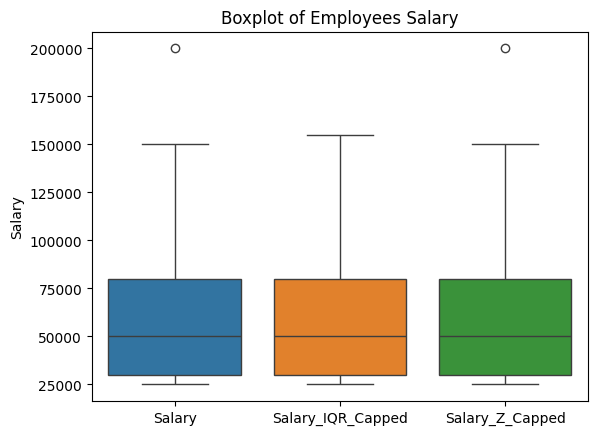

In [39]:
sns.boxplot(data=df[['Salary','Salary_IQR_Capped','Salary_Z_Capped']])
plt.title('Boxplot of Employees Salary')
plt.ylabel('Salary')
plt.show()